In [1]:
import re
import numpy as np
import os
from itertools import combinations
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.models import Model, load_model
from tensorflow.keras import layers, losses, metrics, optimizers, Model, layers, models, optimizers, callbacks
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve

<class 'numpy.ndarray'>
(888, 1920)


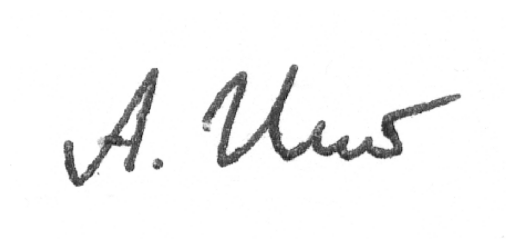

In [2]:
img = cv2.imread(r"train/070/1.png", cv2.IMREAD_GRAYSCALE)
print(type(img))
print(img.shape)
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

In [3]:
def create_signature_dataset(root_dir, person_ids):
    A = []
    B = []
    labels = []

    genuine_data = {}
    forged_data = {}

    def load_images(folder_path):
        images = []
        for img_name in sorted(os.listdir(folder_path)):
            img_path = os.path.join(folder_path, img_name)
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, (222, 120))
            img = img.astype('float32') / 255.0
            images.append(img.reshape(222, 120, 1))
        return images

    for pid in person_ids:
        genuine_folder = os.path.join(root_dir, pid)
        forged_folder  = os.path.join(root_dir, f"{pid}_forg")

        genuine_data[pid] = load_images(genuine_folder)
        forged_data[pid]  = load_images(forged_folder)

    for pid in person_ids:
        imgs = genuine_data[pid]
        for img_a, img_b in combinations(imgs, 2):
            A.append(img_a)
            B.append(img_b)
            labels.append(1)

    num_positive = len(labels)
    print(f"Число положительных пар: {num_positive}")

    negative_pairs = []
    for pid in person_ids:
        genuine_imgs = genuine_data[pid]
        forged_imgs  = forged_data[pid]
        for img_a in genuine_imgs:
            for img_b in forged_imgs:
                negative_pairs.append((img_a, img_b))

    np.random.shuffle(negative_pairs)
    negative_pairs = negative_pairs[:num_positive]

    for img_a, img_b in negative_pairs:
        A.append(img_a)
        B.append(img_b)
        labels.append(0)

    print(f"Число отрицательных пар: {len(negative_pairs)}")

    return np.array(A), np.array(B), np.array(labels)

In [4]:
all_folders = os.listdir("train")
person_ids = sorted([f for f in all_folders if re.fullmatch(r'\d+', f)])

split = int(len(person_ids) * 0.85)
train_folders = person_ids[:split]
test_folders = person_ids[split:]

In [5]:
X1_train, X2_train, y_train = create_signature_dataset('train', train_folders)
print(f"Всего пар в train: {len(X1_train)}")
print(f"Размерность X1_train: {X1_train.shape}")

Число положительных пар: 5707
Число отрицательных пар: 5707
Всего пар в train: 11414
Размерность X1_train: (11414, 222, 120, 1)


In [6]:
X1_test, X2_test, y_test = create_signature_dataset('train', test_folders)
print(f"Всего пар в test: {len(X1_test)}")
print(f"Размерность X1_test: {X1_test.shape}")

Число положительных пар: 919
Число отрицательных пар: 919
Всего пар в test: 1838
Размерность X1_test: (1838, 222, 120, 1)


In [7]:
shape = (222, 120, 1)

x1 = layers.Input(shape=shape)
x2 = layers.Input(shape=shape)

inputs = layers.Input(shape=shape)
feature = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
feature = layers.MaxPooling2D((2, 2))(feature)

feature = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(feature)
feature = layers.MaxPooling2D((2, 2))(feature)

feature = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(feature)
feature = layers.MaxPooling2D((2, 2))(feature)


feature_model = Model(inputs=inputs, outputs=feature)


x1_net = feature_model(x1)
x2_net = feature_model(x2)


net = layers.Subtract()([x1_net, x2_net])

net = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(net)
net = layers.MaxPooling2D((2, 2))(net)

net = layers.Flatten()(net)
net = layers.Dense(64, activation='relu')(net)

net = layers.Dense(1, activation='sigmoid')(net)


classifier = Model(inputs=[x1, x2], outputs=net)

classifier.compile(
    loss=losses.BinaryCrossentropy(),
    optimizer=optimizers.Adam(),
    metrics=['accuracy']
)

In [8]:
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

checkpoint = callbacks.ModelCheckpoint(
    'sign.keras',
    monitor='val_loss',
    save_best_only=True
)

history = classifier.fit(
    [X1_train, X2_train], y_train,
    validation_data=([X1_test, X2_test], y_test),
    epochs=20,
    batch_size=16,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

Epoch 1/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 34s 39ms/step - accuracy: 0.8894 - loss: 0.2548 - val_accuracy: 0.9064 - val_loss: 0.2379
Epoch 2/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.9725 - loss: 0.0701 - val_accuracy: 0.9271 - val_loss: 0.2359
Epoch 3/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 22s 30ms/step - accuracy: 0.9877 - loss: 0.0358 - val_accuracy: 0.9151 - val_loss: 0.2951
Epoch 4/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.9953 - loss: 0.0161 - val_accuracy: 0.9298 - val_loss: 0.2209
Epoch 5/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.9974 - loss: 0.0073 - val_accuracy: 0.9314 - val_loss: 0.2722
Epoch 6/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.9929 - loss: 0.0197 - val_accuracy: 0.8863 - val_loss: 0.4522
Epoch 7/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.9993 - loss: 0.0022 - val_accuracy: 0.8134 - val_loss: 0.8171
Epoch 8/20
714/714 ━━━━━━━━━━━━━━━━━━━━ 22s 31ms/step - accuracy: 0.9952 - loss: 0.0139 - 

In [41]:
classifier = load_model('sign.keras')

58/58 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step
Precision: 0.9478
Recall: 0.9086
ROC AUC: 0.9783


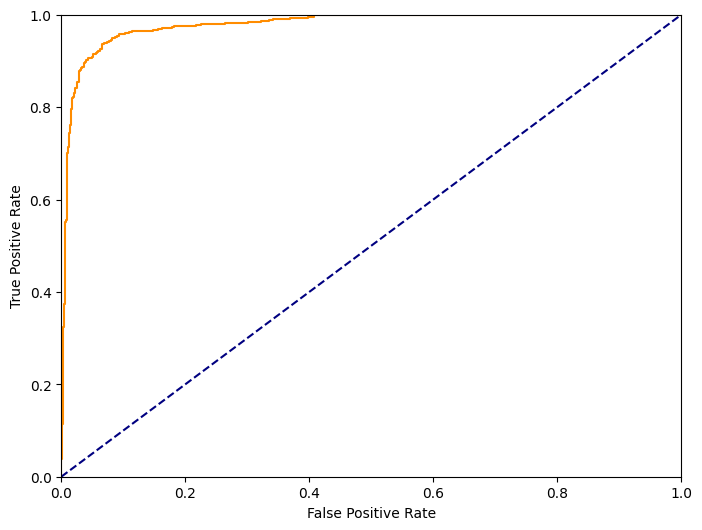

In [11]:
y_pred_prob = classifier.predict([X1_test, X2_test])
y_pred_class = (y_pred_prob > 0.6).astype(int)

precision = precision_score(y_test, y_pred_class)
recall = recall_score(y_test, y_pred_class)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.0])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

In [51]:
def load_and_preprocess(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    img = cv2.resize(img, (222, 120))
    img = img.astype("float32") / 255.0
    img = np.expand_dims(img, axis=-1)
    img = np.expand_dims(img, axis=0)
    return img

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step

Результат сравнения: 0.0000
Подпись сделана разными людьми


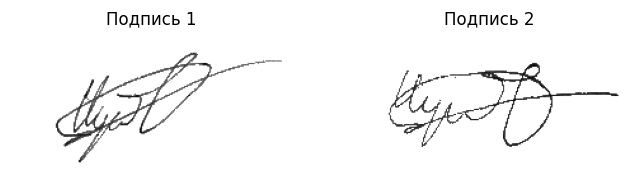

In [68]:
path_1 = 'sign.png'
path_2 = 'fake.png'

img1 = load_and_preprocess(path_1)
img2 = load_and_preprocess(path_2)
img1[img1 > 0.59] = 1.0
img2[img2 > 0.39] = 1.0

prediction = classifier.predict([img1, img2])
score = prediction[0][0]

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img1[0, :, :, 0], cmap='gray')
plt.title("Подпись 1")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2[0, :, :, 0], cmap='gray')
plt.title("Подпись 2")
plt.axis('off')

print(f"\nРезультат сравнения: {score:.4f}")
if score > 0.5:
    print("Подпись сделана одним человеком")
else:
    print("Подпись сделана разными людьми")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step

Результат сравнения: 0.0044
Подпись сделана разными людьми


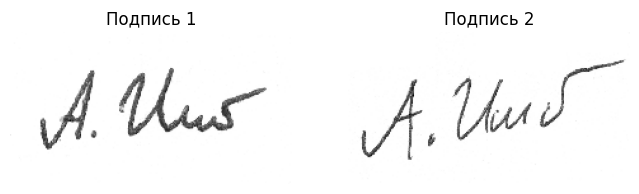

In [69]:
path_1 = r'sign_data\train\070\1.png'
path_2 = r'sign_data\train\070_forg\10.png'

img1 = load_and_preprocess(path_1)
img2 = load_and_preprocess(path_2)

prediction = classifier.predict([img1, img2])
score = prediction[0][0]

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img1[0, :, :, 0], cmap='gray')
plt.title("Подпись 1")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2[0, :, :, 0], cmap='gray')
plt.title("Подпись 2")
plt.axis('off')

print(f"\nРезультат сравнения: {score:.4f}")
if score > 0.5:
    print("Подпись сделана одним человеком")
else:
    print("Подпись сделана разными людьми")

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

Результат сравнения: 0.9654
Подпись сделана одним человеком


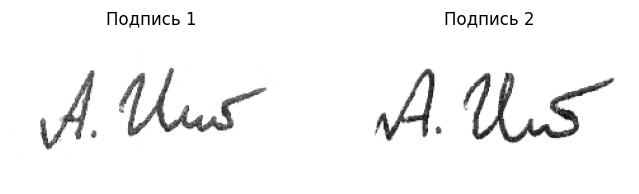

In [70]:
path_1 = r'sign_data\train\070\1.png'
path_2 = r'sign_data\train\070\2.png'

img1 = load_and_preprocess(path_1)
img2 = load_and_preprocess(path_2)

prediction = classifier.predict([img1, img2])
score = prediction[0][0]

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img1[0, :, :, 0], cmap='gray')
plt.title("Подпись 1")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img2[0, :, :, 0], cmap='gray')
plt.title("Подпись 2")
plt.axis('off')

print(f"\nРезультат сравнения: {score:.4f}")
if score > 0.5:
    print("Подпись сделана одним человеком")
else:
    print("Подпись сделана разными людьми")

plt.show()